# Statistical Analysis

Descriptive Analysis (EDA)

1. Data Loading & Overview
2. Data Quality Checks

Statistical Analysis

1. Descriptive Statistics
2. Correlation Analysis & Hypotheses Testing
    - Is there a statistically significant relationship between DTI ratio and loan default?
    - Does the average loan amount differ significantly between defaulted and non-defaulted loans?
    - Is loan purpose significantly associated with loan default?
    - Are borrowers with less than 2 years of employment significantly more likely to default than borrowers with 2 or more years of employment?

In [58]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
import mysql.connector
from dotenv import load_dotenv
import os

In [5]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="pandas only supports SQLAlchemy connectable"
)

In [6]:
load_dotenv()

conn = mysql.connector.connect(
    host=os.getenv("MYSQL_HOST"),
    user=os.getenv("MYSQL_USER"),
    password=os.getenv("MYSQL_PASSWORD"),
    database=os.getenv("MYSQL_DATABASE")
)

In [7]:
conn.is_connected()

True

# Descriptive Analysis (EDA)

1. Data Loading & Overview

In [44]:
query = """
SELECT
    l.loan_id,
    b.borrower_id,
    b.annual_income,
    b.existing_monthly_debt,
    b.credit_score,
    b.employment_status,
    b.years_employed,
    l.loan_amount,
    l.term_months,
    l.interest_rate,
    l.monthly_payment,
    l.dti_ratio,
    l.loan_purpose,
    l.loan_status,
    l.defaulted
FROM borrower_profiles b
JOIN loan_applications l
    ON b.borrower_id = l.borrower_id
"""

df = pd.read_sql(query, conn)

In [20]:
# Dataset overview
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())
display(df.dtypes.to_frame("Data Type"))
display(df.describe(include="all").T)

Number of rows: 601
Number of columns: 15


,loan_id,borrower_id,annual_income,existing_monthly_debt,credit_score,employment_status,years_employed,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_purpose,loan_status,defaulted
0,LN-00001,BRW-0001,31020.0,892.0,596,Self-Employed,6,16100.0,36,13.05,542.86,55.5,Vacation,Paid Off,0
1,LN-00002,BRW-0001,31020.0,892.0,596,Self-Employed,6,5600.0,48,14.21,153.62,40.4,Major Purchase,Default,1
2,LN-00003,BRW-0002,40188.0,869.0,543,Full-Time,4,44700.0,36,12.37,1492.59,70.5,Moving,Paid Off,0
3,LN-00004,BRW-0003,41014.0,1806.0,611,Contract,22,9200.0,48,11.18,238.58,59.8,Auto Loan,Default,1
4,LN-00005,BRW-0004,35036.0,928.0,701,Full-Time,19,11200.0,36,9.66,359.61,44.1,Moving,Current,0


,Data Type
loan_id,object
borrower_id,object
annual_income,float64
existing_monthly_debt,float64
credit_score,int64
employment_status,object
years_employed,int64
loan_amount,float64
term_months,int64
interest_rate,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,601,601,LN-00601,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borrower_id,601,500,BRW-0472,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income,601.0,NaN,NaN,NaN,65056.509151,29217.561391,12549.0,43022.0,59967.0,81309.0,157047.0
existing_monthly_debt,601.0,NaN,NaN,NaN,1624.184692,1124.974225,124.0,791.0,1316.0,2207.0,6130.0
credit_score,601.0,NaN,NaN,NaN,705.745424,98.216462,528.0,617.0,707.0,796.0,850.0
employment_status,601,5,Full-Time,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
years_employed,601.0,NaN,NaN,NaN,10.920133,9.353267,0.0,3.0,8.0,17.0,35.0
loan_amount,601.0,NaN,NaN,NaN,22148.252912,13215.261422,2000.0,10900.0,20400.0,32700.0,49800.0
term_months,601.0,NaN,NaN,NaN,36.539101,16.898192,12.0,24.0,36.0,48.0,60.0
interest_rate,601.0,NaN,NaN,NaN,10.641331,2.251153,5.86,8.94,10.54,12.33,15.86


The dataset contains 601 loan records across 15 columns, representing 500 unique borrowers. No missing values were identified in the displayed summary statistics. The average annual income is approximately 65,056.51, while the average loan amount is 22,148.25 and the average DTI ratio is 49.68%. The observed default rate is 24.29%, which exceeds the business target of 12%. These initial findings highlight the importance of investigating the relationship between borrower debt burden, credit characteristics, employment tenure, and loan default risk. Further statistical analysis is required to determine whether the observed relationships are statistically significant.

In [22]:
# Missing values
missing_values = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

,missing_count,missing_percentage
loan_id,0,0.0
borrower_id,0,0.0
annual_income,0,0.0
existing_monthly_debt,0,0.0
credit_score,0,0.0
employment_status,0,0.0
years_employed,0,0.0
loan_amount,0,0.0
term_months,0,0.0
interest_rate,0,0.0


Exact duplicate rows: 0


The dataset contains 601 observations across 15 variables, with no missing values or exact duplicate rows detected. This indicates that the dataset is complete in terms of missing values and exact duplicates. However, further validation is necessary to ensure data consistency, accuracy, and validity before proceeding with the analysis.

In [23]:
# Checking the numerical columns is there an error values 

numeric_cols = [
    "annual_income",
    "existing_monthly_debt",
    "credit_score",
    "years_employed",
    "term_months",
    "interest_rate",
    "monthly_payment",
    "dti_ratio",
    "defaulted"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df[numeric_cols].isnull().sum().to_frame("Missing after conversion"))

,Missing after conversion
annual_income,0
existing_monthly_debt,0
credit_score,0
years_employed,0
term_months,0
interest_rate,0
monthly_payment,0
dti_ratio,0
defaulted,0


No missing values were detected across the 9 numerical variables after conversion to numeric data types. This indicates that all values were successfully converted without introducing additional missing values. The numerical variables are therefore ready for further statistical analysis, although their validity and consistency should still be verified.

2. Data Quality Checks

In [25]:
validation_summary = pd.DataFrame({
    "Check": [
        "Missing values",
        "Duplicate loan IDs",
        "Invalid default values",
        "Invalid credit scores",
        "Non-positive loan amounts",
        "Non-positive annual income",
        "Negative DTI"
    ],
    "Issues Found": [
        df.isnull().sum().sum(),
        df["loan_id"].duplicated().sum(),
        (~df["defaulted"].isin([0, 1])).sum(),
        (~df["credit_score"].between(300, 850)).sum(),
        (df["loan_amount"] <= 0).sum(),
        (df["annual_income"] <= 0).sum(),
        (df["dti_ratio"] < 0).sum()
    ]
})

display(validation_summary)

,Check,Issues Found
0,Missing values,0
1,Duplicate loan IDs,0
2,Invalid default values,0
3,Invalid credit scores,0
4,Non-positive loan amounts,0
5,Non-positive annual income,0
6,Negative DTI,0


The dataset was evaluated against seven data quality checks, covering missing values, duplicate loan IDs, invalid default indicators, credit score ranges, non-positive loan amounts, non-positive annual income, and negative DTI values.

All seven checks returned zero issues. This indicates that the dataset meets the tested completeness and validity rules, with no duplicate loan IDs or invalid values identified in these checks.

However, these results do not independently confirm the accuracy or consistency of every record. Additional validation, including recalculating DTI ratios and checking categorical consistency, is required before proceeding with statistical analysis.

# Statistical Analysis

1. Descriptive Statistic

In [32]:
df.describe().round(2)

,annual_income,existing_monthly_debt,credit_score,years_employed,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,defaulted
count,601.00,601.00,601.00,601.00,601.00,601.00,601.00,601.00,601.00,601.00
mean,65056.51,1624.18,705.75,10.92,22148.25,36.54,10.64,948.34,49.68,0.24
std,29217.56,1124.97,98.22,9.35,13215.26,16.90,2.25,864.96,24.11,0.43
min,12549.00,124.00,528.00,0.00,2000.00,12.00,5.86,44.14,7.60,0.00
25%,43022.00,791.00,617.00,3.00,10900.00,24.00,8.94,359.86,32.20,0.00
50%,59967.00,1316.00,707.00,8.00,20400.00,36.00,10.54,684.87,48.10,0.00
75%,81309.00,2207.00,796.00,17.00,32700.00,48.00,12.33,1165.20,62.40,0.00
max,157047.00,6130.00,850.00,35.00,49800.00,60.00,15.86,4262.69,177.40,1.00


The dataset contains 601 loan records. The average annual income is approximately 65,056.51, while the average loan amount is 22,148.25 and the average loan term is 36.54 months. The average DTI ratio is 49.68%, with a standard deviation of 24.11 percentage points, indicating substantial variation in borrowers' debt burden.

The observed default rate is 24.29%, exceeding the business target of 12%. Several variables, including annual income, existing monthly debt, loan amount, and monthly payment, have means higher than their medians, suggesting potential right-skewness that should be investigated further. These descriptive findings provide an initial overview of borrower and loan characteristics but do not establish which factors are statistically associated with default.

2. Correlation Analysis

-- Is the relationship between DTI and default statistically significant?

Metode: Point-Biserial Correlation

- H₀: There is no significant linear relationship between DTI ratio and loan default.

- H₁: There is a significant linear relationship between DTI ratio and loan default.

In [ ]:
# Prepare the 2 variables dti ratio vs default

corr_df = df[["dti_ratio", "defaulted"]].dropna()

print("Total observations:", len(corr_df))
print(corr_df["defaulted"].value_counts())

Total observations: 601
defaulted
0    455
1    146
Name: count, dtype: int64


In [34]:
# Measure point-biserial correlation
corr, p_value = stats.pointbiserialr(
    corr_df["defaulted"],
    corr_df["dti_ratio"]
)

print(f"Correlation coefficient: {corr:.4f}")
print(f"P-value: {p_value:.4f}")

Correlation coefficient: 0.1925
P-value: 0.0000


The point-biserial correlation analysis identified a weak positive relationship between debt-to-income (DTI) ratio and loan default (r = 0.1925). The relationship was statistically significant at the 5% significance level (p < 0.05). This suggests that borrowers with higher DTI ratios tend to have a greater likelihood of default in the observed dataset. However, the weak correlation indicates that DTI alone does not fully explain default risk, and the result does not establish causation. Other borrower and loan characteristics should be investigated to provide a more comprehensive assessment of default risk.

In [41]:
query = """
WITH dti_cte AS(
	SELECT
		loan_id,
        dti_ratio,
        defaulted,
		CASE
			WHEN dti_ratio < 40 THEN 'less than 40%'
            WHEN dti_ratio < 60 THEN '40-59.9%'
            WHEN dti_ratio < 80 THEN '60-79.9%'
            ELSE '80% or higher'
		END AS dti_bands
        FROM loan_applications
)
SELECT
	dti_bands,
    COUNT(*) AS total_loans,
    SUM(defaulted) AS defaulted_loans,
    ROUND(SUM(defaulted) * 100 / COUNT(*), 2) AS defaulted_rate
FROM dti_cte
GROUP BY dti_bands
ORDER BY
	CASE dti_bands
        WHEN 'less than 40%' THEN 1
        WHEN '40-59.9%' THEN 2
        WHEN '60-79.9%' THEN 3
        WHEN '80% or higher' THEN 4
    END ASC;
"""

df_dti_bands = pd.read_sql(query, conn)

df_dti_bands

,dti_bands,total_loans,defaulted_loans,defaulted_rate
0,less than 40%,233,30.0,12.88
1,40-59.9%,196,54.0,27.55
2,60-79.9%,120,43.0,35.83
3,80% or higher,52,19.0,36.54


In [63]:
corr_df = corr_df.copy()

corr_df["dti_band"] = pd.cut(
    corr_df["dti_ratio"],
    bins=[0, 40, 60, 80, np.inf],
    labels=["<40%", "40–59.9%", "60–79.9%", "80%+"],
    right=False
)

dti_summary = (
    corr_df.groupby("dti_band", observed=False)
    .agg(
        total_loans=("defaulted", "count"),
        default_rate=("defaulted", "mean")
    )
    .reset_index()
)

dti_summary["default_rate"] *= 100

display(dti_summary)

,dti_band,total_loans,default_rate
0,<40%,233,12.875536
1,40–59.9%,196,27.551020
2,60–79.9%,120,35.833333
3,80%+,52,36.538462


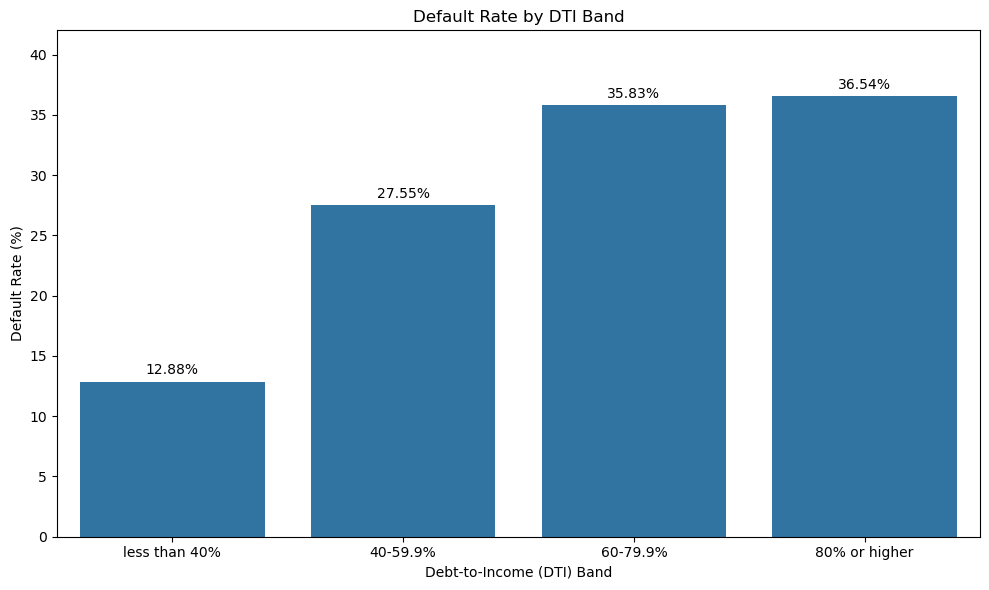

In [43]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_dti_bands,
    x="dti_bands",
    y="defaulted_rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3
)

plt.title("Default Rate by DTI Band")
plt.xlabel("Debt-to-Income (DTI) Band")
plt.ylabel("Default Rate (%)")
plt.ylim(0, df["defaulted_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

-- Does the average loan amount differ significantly between defaulted and non-defaulted loans?

Metode: Welch's t-test

- H₀: The mean loan amount is equal for defaulted and non-defaulted loans.

- H₁: The mean loan amount differs between defaulted and non-defaulted loans.

In [45]:
defaulted_loans = df.loc[
    df["defaulted"] == 1, "loan_amount"
].dropna()

non_defaulted_loans = df.loc[
    df["defaulted"] == 0, "loan_amount"
].dropna()

In [46]:
loan_summary = pd.DataFrame({
    "Group": ["Defaulted", "Non-Defaulted"],
    "Count": [
        len(defaulted_loans),
        len(non_defaulted_loans)
    ],
    "Mean Loan Amount": [
        defaulted_loans.mean(),
        non_defaulted_loans.mean()
    ],
    "Median Loan Amount": [
        defaulted_loans.median(),
        non_defaulted_loans.median()
    ],
    "Standard Deviation": [
        defaulted_loans.std(),
        non_defaulted_loans.std()
    ]
})

display(loan_summary.round(2))

,Group,Count,Mean Loan Amount,Median Loan Amount,Standard Deviation
0,Defaulted,146,22570.55,20400.0,13172.44
1,Non-Defaulted,455,22012.75,20400.0,13240.58


In [47]:
t_stat, p_value = stats.ttest_ind(
    defaulted_loans,
    non_defaulted_loans,
    equal_var=False,
    alternative="two-sided"
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

T-statistic: 0.4446
P-value: 0.656969


Welch's t-test was conducted to examine whether the average loan amount differed significantly between defaulted and non-defaulted loans. The test returned a t-statistic of 0.4446 and a p-value of 0.656969. Since the p-value exceeds the 0.05 significance level, the null hypothesis was not rejected. Therefore, the analysis found insufficient statistical evidence to conclude that average loan amounts differ significantly between the two groups. This suggests that loan amount alone may not be a sufficient indicator for distinguishing default risk in this dataset.

In [50]:
print(f"Average loan amount (defaulted): {defaulted_loans.mean():,.2f}")
print(f"Average loan amount (non-defaulted): {non_defaulted_loans.mean():,.2f}")

difference = defaulted_loans.mean() - non_defaulted_loans.mean()

print(f"Difference in means: {difference:,.2f}")

Average loan amount (defaulted): 22,570.55
Average loan amount (non-defaulted): 22,012.75
Difference in means: 557.80


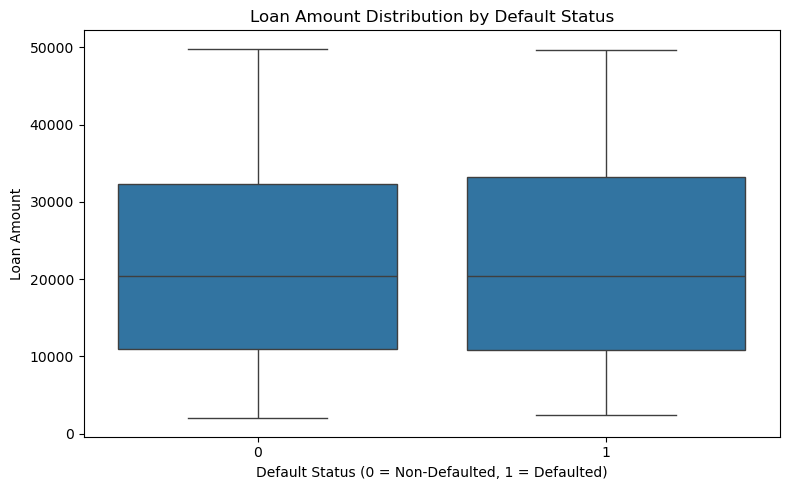

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="defaulted",
    y="loan_amount"
)

plt.title("Loan Amount Distribution by Default Status")
plt.xlabel("Default Status (0 = Non-Defaulted, 1 = Defaulted)")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

-- Are default rates significantly associated with loan purpose?

Metode: Chi-square Test of Independence

- H₀: Loan purpose and default status are independent; there is no significant association between them.

- H₁: Loan purpose and default status are not independent; there is a significant association between them.

In [52]:
contingency_table = pd.crosstab(
    df["loan_purpose"],
    df["defaulted"]
)

contingency_table.columns = [
    "Non-Defaulted",
    "Defaulted"
]

display(contingency_table)

,Non-Defaulted,Defaulted
loan_purpose,,
Auto Loan,43,16
Business Loan,44,14
Debt Consolidation,40,11
Education,41,12
Home Improvement,50,20
Major Purchase,53,15
Medical Expenses,54,14
Moving,44,12
Vacation,48,14


In [53]:
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

Chi-square statistic: 4.1550
Degrees of freedom: 9
P-value: 0.900917


In [54]:
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Minimum expected frequency:", expected.min())
print("Cells with expected frequency < 5:", (expected < 5).sum())

,Non-Defaulted,Defaulted
loan_purpose,,
Auto Loan,44.67,14.33
Business Loan,43.91,14.09
Debt Consolidation,38.61,12.39
Education,40.12,12.88
Home Improvement,53.00,17.00
Major Purchase,51.48,16.52
Medical Expenses,51.48,16.52
Moving,42.40,13.60
Vacation,46.94,15.06


Minimum expected frequency: 12.389351081530782
Cells with expected frequency < 5: 0


A Chi-square test of independence was conducted to examine the association between loan purpose and default status. The test produced a chi-square statistic of 4.1550 with 9 degrees of freedom and a p-value of 0.900917. Since the p-value exceeds the 0.05 significance level, the null hypothesis was not rejected. Therefore, the analysis found insufficient statistical evidence of an association between loan purpose and default status in this dataset. Although observed default rates varied across loan purposes, these differences were not statistically significant. The expected-frequency assumption was also satisfied, with no expected cell frequencies below 5.

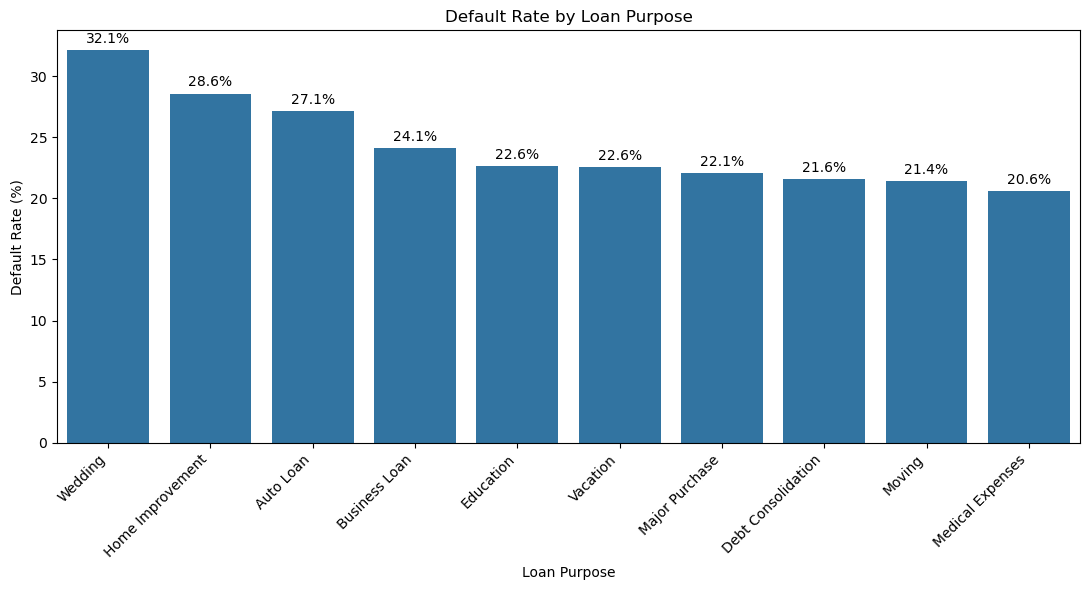

In [56]:
purpose_summary = (
    df.groupby("loan_purpose", observed=True)
    .agg(
        total_loans=("defaulted", "count"),
        default_rate=("defaulted", "mean")
    )
    .reset_index()
)

purpose_summary["default_rate"] *= 100

purpose_summary = purpose_summary.sort_values(
    "default_rate",
    ascending=False
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=purpose_summary,
    x="loan_purpose",
    y="default_rate"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

-- Are borrowers with less than 2 years of employment significantly more likely to default?

Metode: One-sided Two-Proportion Z-Test

- H₀: The default proportion among borrowers with less than 2 years of employment is not higher than that among borrowers with 2 or more years of employment.

- H₁: The default proportion among borrowers with less than 2 years of employment is higher than that among borrowers with 2 or more years of employment.

In [57]:
# Kelompok employment tenure
short_tenure = df[df["years_employed"] < 2]
long_tenure = df[df["years_employed"] >= 2]

# Jumlah default di masing-masing kelompok
defaults = np.array([
    short_tenure["defaulted"].sum(),
    long_tenure["defaulted"].sum()
])

# Total pinjaman di masing-masing kelompok
totals = np.array([
    short_tenure["defaulted"].count(),
    long_tenure["defaulted"].count()
])

print("Defaults:", defaults)
print("Total loans:", totals)

Defaults: [ 29 117]
Total loans: [ 84 517]


In [59]:
rate_short = defaults[0] / totals[0]
rate_long = defaults[1] / totals[1]

print(f"Default rate (<2 years): {rate_short:.2%}")
print(f"Default rate (2+ years): {rate_long:.2%}")
print(
    f"Difference: {(rate_short - rate_long) * 100:.2f} percentage points"
)

Default rate (<2 years): 34.52%
Default rate (2+ years): 22.63%
Difference: 11.89 percentage points


In [60]:
z_stat, p_value = proportions_ztest(
    count=defaults,
    nobs=totals,
    alternative="larger"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

Z-statistic: 2.3574
P-value: 0.009201


A one-sided two-proportion z-test was conducted to determine whether borrowers with less than two years of employment had a higher default rate than borrowers with two or more years of employment. The default rate was 34.52% for the shorter-tenure group (29 of 84 loans), compared with 22.63% for the longer-tenure group (117 of 517 loans), a difference of 11.89 percentage points. The test produced a z-statistic of 2.3574 and a p-value of 0.009201. Since the p-value is below the 0.05 significance level, the null hypothesis was rejected. The results provide statistical evidence that borrowers with less than two years of employment had a higher default proportion in this dataset. However, this association does not establish causation, and other borrower characteristics should also be considered in credit risk assessment.

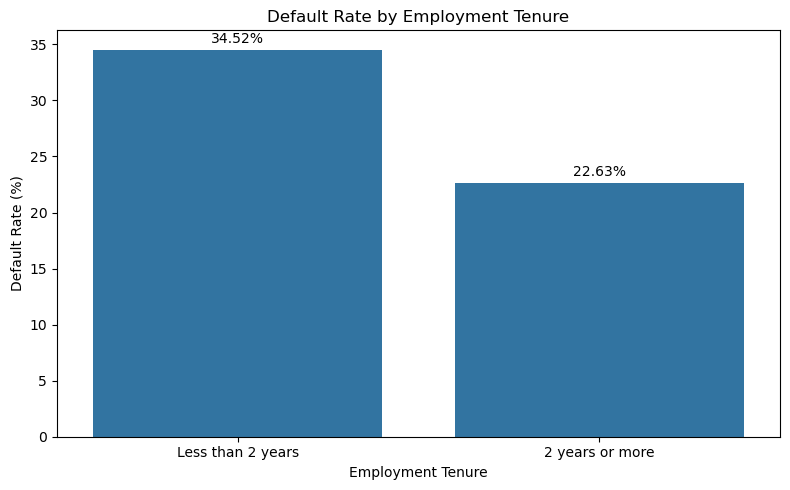

In [61]:
employment_summary = pd.DataFrame({
    "Employment Tenure": ["Less than 2 years", "2 years or more"],
    "Default Rate": [rate_short * 100, rate_long * 100]
})

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=employment_summary,
    x="Employment Tenure",
    y="Default Rate"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Default Rate by Employment Tenure")
plt.xlabel("Employment Tenure")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

# Key Findings

The statistical analysis identified two notable findings. First, DTI ratio had a weak but statistically significant positive association with loan default (r = 0.1925, p < 0.001). Second, borrowers with less than two years of employment had a significantly higher observed default rate than those with longer employment tenure (34.52% vs. 22.63%, p = 0.009201).

In contrast, the analysis found insufficient statistical evidence of a difference in average loan amount between defaulted and non-defaulted loans (p = 0.656969), or an association between loan purpose and default status (p = 0.900917).

These findings suggest that borrower debt burden and employment tenure warrant further investigation in credit risk assessment. However, the results indicate associations rather than causal relationships, and additional borrower characteristics should be considered when evaluating default risk.